<!-- repro-header -->
> **Reproducibility header**
>
> - **Aim:** Cell morphology vs. normalized uRNA source score, per cell type (mouse brain).
> - **Manuscript panels:** ED Fig. 7C
> - **Inputs:** `data_annotated_lambda0.5.zarr`
> - **Outputs:** Morphology vs. source-score scatters
> - **Environment / kernel:** `troutpy_drvi`
> - Data root: `/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy` (ROIs on Zenodo 10.5281/zenodo.17446348). 


# Morphology vs. uRNA association, by cell type (reviewer point 2)

`xenium_msbrain_5k` only — the sole dataset in the project with both real biological `cell_type`
annotation (see `0_annotation_msbrain_5k.ipynb`) and a finalized, lambda-tuned `urna_source_score`
(`recompute_source_score_final_lambda05.py`, `lmbda=0.5`, `cell_type_col="cell_type"`).
`sdata['table'].obs` already has all `add_morphological_metrics` columns alongside `cell_type`,
`leiden`, `urna_source_score`, and `n_counts` in the same table — nothing is recomputed here,
this is read-only analysis.

This is the cell-type-resolved complement to the bulk, all-dataset comparison in
[13_morphology_urna_association.ipynb](../3_analysis_of_results/13_morphology_urna_association.ipynb),
which uses unsupervised Leiden-cluster diversity as a composition-complexity proxy across ~19
datasets. Here, for this one annotated dataset, we use the real `cell_type` labels instead.

# Read dataset

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData

import matplotlib
import matplotlib.pyplot as plt
import os
import sys
import numpy as np
import pandas as pd
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path
from scipy.stats import entropy, spearmanr

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [2]:
from troutpy import pl
from troutpy import tl
from troutpy import pp

In [3]:
# Define base directories
data_dir = Path("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_msbrain_5k")
saving_path = Path("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k/morphology_urna_association")

Path(saving_path).mkdir(parents=True, exist_ok=True)

# Read spatial data using the / operator for clean path joining
sdata = sd.read_zarr(data_dir / "data_annotated_lambda0.5.zarr")

version mismatch: detected: RasterFormatV02, requested: FormatV04


In [4]:
cell_type_key = 'cell_type'

morphology_cols = [
    "area", "perimeter", "solidity", "major_axis_length", "equivalent_diameter",
    "circularity", "protrusion_length", "morphological_complexity",
]

obs = sdata["table"].obs.copy()
obs["normalized_urna_source_score"] = obs["urna_source_score"] / obs["n_counts"]

obs["cell_type"].value_counts()

cell_type
DG                   1665
Oligodendrocytes     1290
Astrocytes           1139
CA1-2                1090
Endothelial           614
EXC neurons Thal.     497
SMC/Pericytes         429
EXC. neurons CTX      413
CA3                   405
Microglia             307
Ependymal cells       300
INH neurons           274
OPC                   258
Astrocytes Thal.      222
SGZ Neuroblasts       172
Cajal-Retzius          40
Choroid plexus         38
INH neurons CP         32
Name: count, dtype: int64

## Per-cell-type morphology + uRNA-source-score summary

In [5]:
celltype_summary = obs.groupby("cell_type", observed=True).agg(
    n_cells=("cell_type", "size"),
    **{f"{c}_mean": (c, "mean") for c in morphology_cols},
    urna_source_score_mean=("urna_source_score", "mean"),
    normalized_urna_source_score_mean=("normalized_urna_source_score", "mean"),
).sort_values("normalized_urna_source_score_mean", ascending=False)

celltype_summary.to_csv(os.path.join(saving_path, "celltype_morphology_urna_summary.csv"))
celltype_summary

,n_cells,area_mean,perimeter_mean,solidity_mean,major_axis_length_mean,equivalent_diameter_mean,circularity_mean,protrusion_length_mean,morphological_complexity_mean,urna_source_score_mean,normalized_urna_source_score_mean
cell_type,,,,,,,,,,,
Astrocytes Thal.,222,2068.449541,173.074558,0.946099,58.694040,48.800031,0.789015,4.947005,0.053901,198.953629,0.291847
Astrocytes,1139,1725.120287,161.816067,0.935134,55.739308,44.360416,0.759111,5.689446,0.064866,189.203157,0.286007
Endothelial,614,1817.734797,164.400131,0.939898,56.586633,45.410529,0.768452,5.588052,0.060102,108.572305,0.223673
EXC. neurons CTX,413,1916.419598,173.714509,0.933451,59.867411,47.501044,0.752673,6.183183,0.066549,362.355685,0.218304
OPC,258,1749.000000,164.023204,0.939270,57.302967,45.129951,0.765752,6.086508,0.060730,171.971195,0.216870
Microglia,307,1726.762542,163.760770,0.935990,56.512162,44.915688,0.759950,5.798237,0.064010,126.126737,0.195134
EXC neurons Thal.,497,1994.008197,174.013951,0.941170,60.428458,47.965092,0.767745,6.231683,0.058830,367.644807,0.186134
INH neurons,274,1967.581481,176.091969,0.931622,60.664024,47.703338,0.741465,6.480343,0.068378,369.244830,0.181430
CA3,405,3254.032178,234.020269,0.913767,78.266861,61.223365,0.696652,8.521748,0.086233,381.803526,0.161336


## Cell type composition complexity (real annotation, single dataset)

In [6]:
props = obs["cell_type"].value_counts(normalize=True)
n_types = len(props)
celltype_shannon = entropy(props, base=2)
celltype_evenness = celltype_shannon / np.log2(n_types) if n_types > 1 else np.nan
celltype_simpson = 1 - float((props ** 2).sum())

print(f"n_cell_types={n_types}")
print(f"Shannon entropy={celltype_shannon:.3f} bits")
print(f"Evenness={celltype_evenness:.3f}")
print(f"Simpson index={celltype_simpson:.3f}")

n_cell_types=18
Shannon entropy=3.631 bits
Evenness=0.871
Simpson index=0.900


## Per-cell-type morphology <-> uRNA correlation

Within each cell type (min 30 cells), Spearman correlation between `normalized_urna_source_score`
and each morphology metric. Types below the minimum cell count are excluded rather than
silently plotted with an unreliable estimate.

In [7]:
MIN_N = 30
corr_records = []
for ct, sub in obs.groupby("cell_type", observed=True):
    for m in morphology_cols:
        # scipy.stats.spearmanr returns NaN if the input contains ANY NaN/inf (default
        # nan_policy="propagate") -- a small fraction of cells have missing morphology values
        # (e.g. edge-of-image regionprops artifacts), so drop those pairwise per metric rather
        # than letting a handful of bad cells null out the whole cell type's correlation.
        pair = sub[[m, "normalized_urna_source_score"]].replace([np.inf, -np.inf], np.nan).dropna()
        if len(pair) < MIN_N:
            continue
        r, p = spearmanr(pair[m], pair["normalized_urna_source_score"])
        corr_records.append({"cell_type": ct, "morphology_metric": m, "n": len(pair), "spearman_r": r, "p_value": p})

celltype_corr_df = pd.DataFrame(corr_records)
celltype_corr_df.to_csv(os.path.join(saving_path, "celltype_morphology_urna_correlations.csv"), index=False)
celltype_corr_df.sort_values("spearman_r")

,cell_type,morphology_metric,n,spearman_r,p_value
79,Endothelial,morphological_complexity,592,-0.210213,2.447591e-07
135,SMC/Pericytes,morphological_complexity,418,-0.180224,2.121957e-04
40,Choroid plexus,area,36,-0.175547,3.057929e-01
44,Choroid plexus,equivalent_diameter,36,-0.175547,3.057929e-01
134,SMC/Pericytes,protrusion_length,418,-0.174854,3.282738e-04
...,...,...,...,...,...
66,EXC. neurons CTX,solidity,398,0.173055,5.247667e-04
130,SMC/Pericytes,solidity,418,0.180224,2.121957e-04
77,Endothelial,circularity,592,0.181771,8.568202e-06
133,SMC/Pericytes,circularity,418,0.204767,2.456988e-05


## Plots

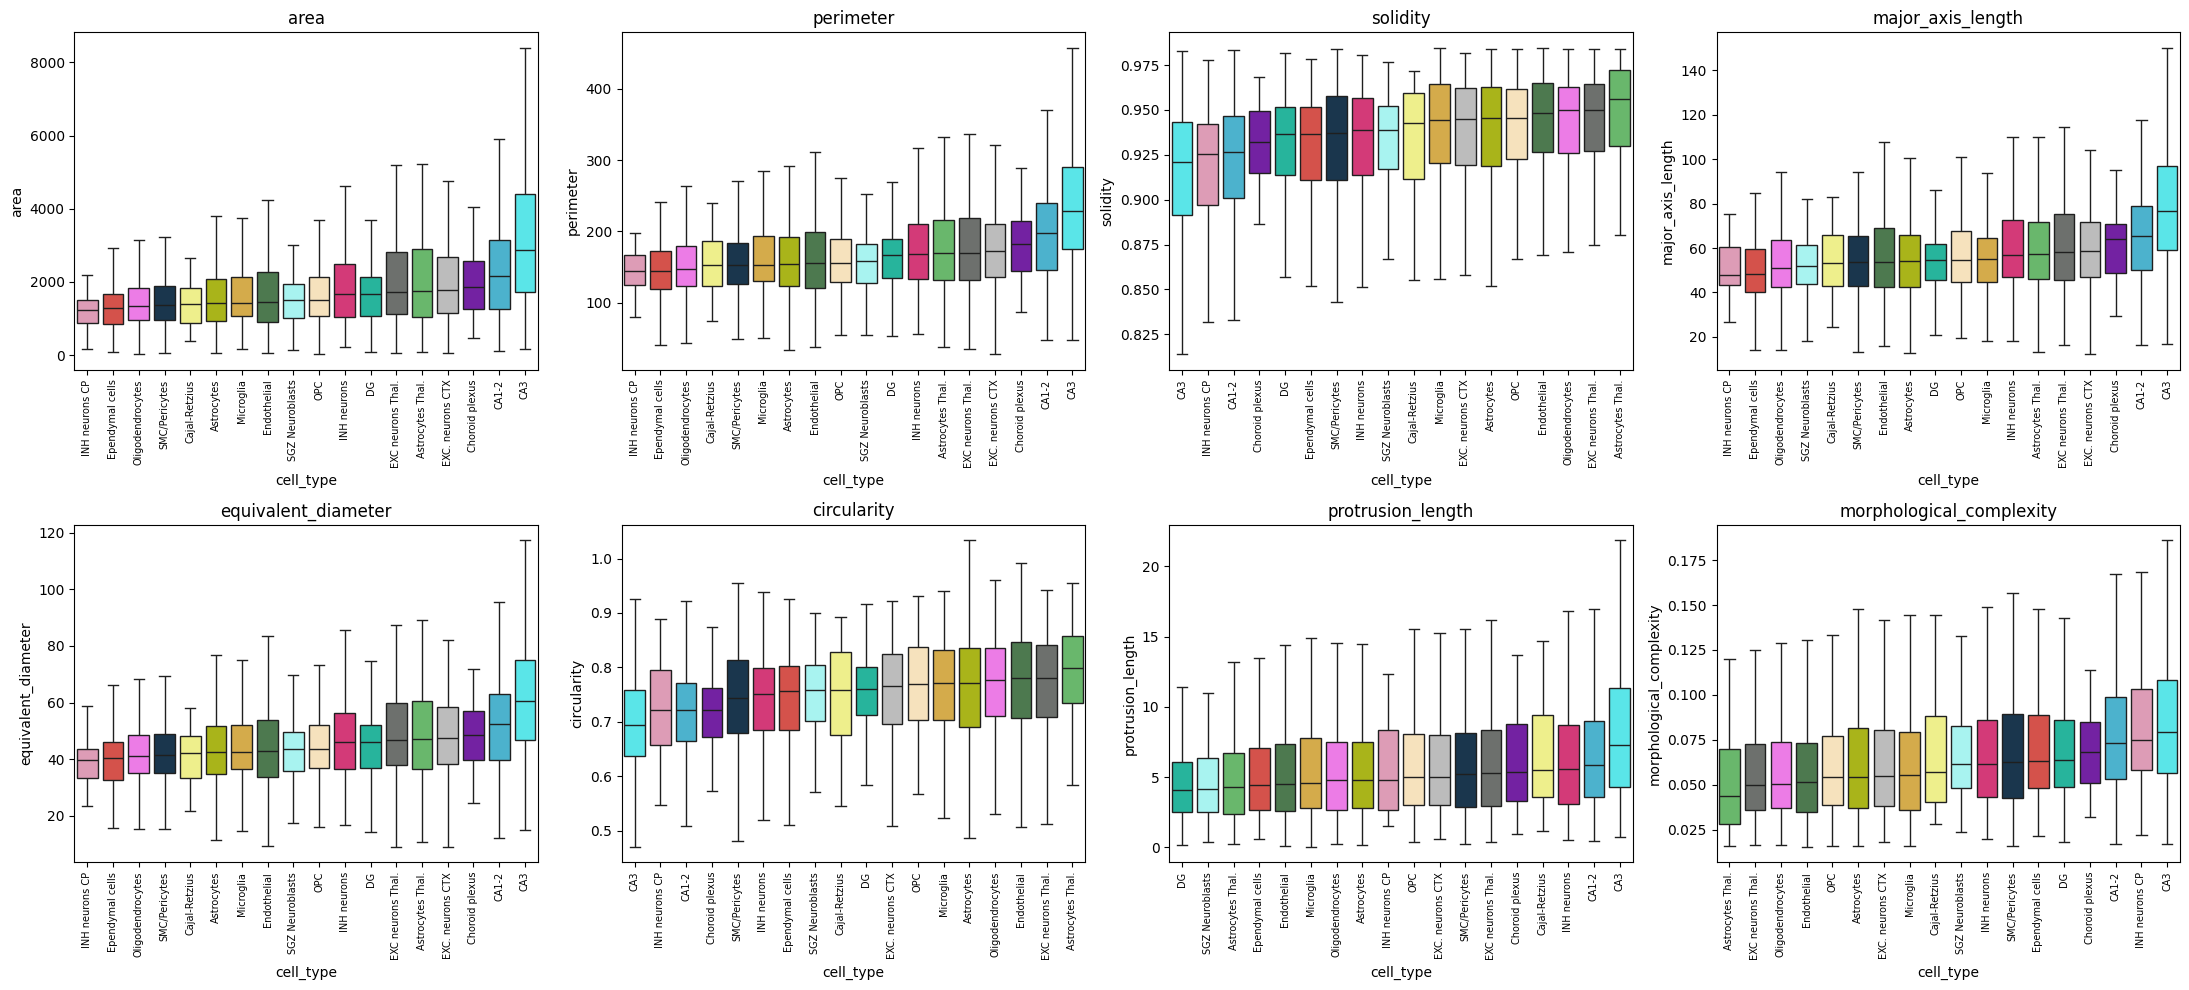

In [8]:
celltype_colors = None
if "cell_type_colors" in sdata["table"].uns:
    cats = sdata["table"].obs["cell_type"].cat.categories
    celltype_colors = dict(zip(cats, sdata["table"].uns["cell_type_colors"]))

fig, axes = plt.subplots(2, 4, figsize=(22, 10))
for ax, m in zip(axes.flat, morphology_cols):
    order = obs.groupby("cell_type", observed=True)[m].median().sort_values().index
    sns.boxplot(data=obs, x="cell_type", y=m, order=order, palette=celltype_colors,
                hue="cell_type", legend=False, ax=ax, showfliers=False)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90, fontsize=7)
    ax.set_title(m)
plt.tight_layout()
plt.savefig(os.path.join(saving_path, "celltype_morphology_boxplots.pdf"), format="pdf", bbox_inches="tight")
plt.show()

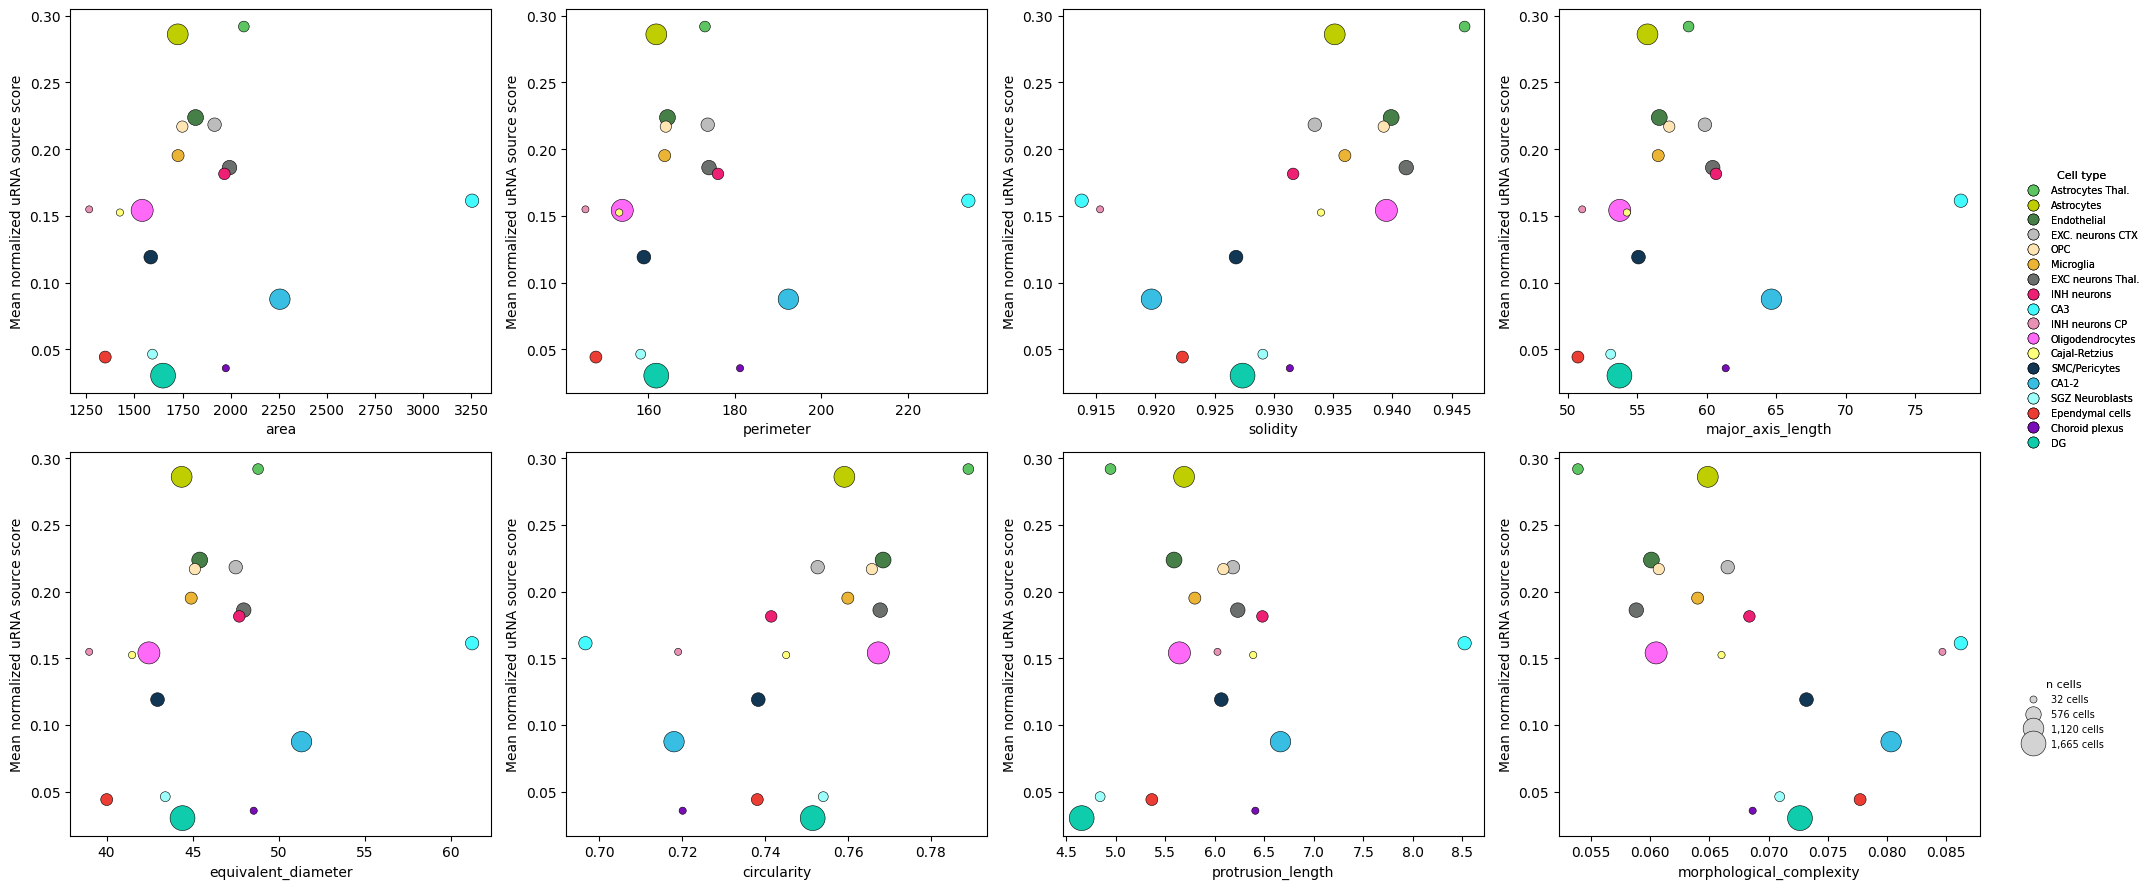

In [9]:
from matplotlib.lines import Line2D

sub_full = celltype_summary.reset_index()
size_scale = lambda n: n / sub_full["n_cells"].max() * 300 + 20

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, m in zip(axes.flat, morphology_cols):
    colors = sub_full["cell_type"].map(celltype_colors) if celltype_colors is not None else None
    ax.scatter(sub_full[f"{m}_mean"], sub_full["normalized_urna_source_score_mean"],
               s=size_scale(sub_full["n_cells"]),
               c=colors, edgecolor="black", linewidth=0.4)
    ax.set_xlabel(m)
    ax.set_ylabel("Mean normalized uRNA source score")

color_handles = [
    Line2D([0], [0], marker="o", linestyle="", markerfacecolor=celltype_colors[ct],
           markeredgecolor="black", markeredgewidth=0.4, markersize=8, label=ct)
    for ct in sub_full["cell_type"]
] if celltype_colors is not None else []

n_min, n_max = sub_full["n_cells"].min(), sub_full["n_cells"].max()
size_ticks = sorted(set(int(v) for v in np.linspace(n_min, n_max, 4)))
size_handles = [
    Line2D([0], [0], marker="o", linestyle="", markerfacecolor="lightgray",
           markeredgecolor="black", markeredgewidth=0.4,
           markersize=np.sqrt(size_scale(n)), label=f"{n:,} cells")
    for n in size_ticks
]

color_legend = fig.legend(handles=color_handles, title="Cell type", loc="center left",
                           bbox_to_anchor=(1.01, 0.65), fontsize=7, title_fontsize=8, frameon=False)
fig.add_artist(color_legend)
fig.legend(handles=size_handles, title="n cells", loc="center left",
           bbox_to_anchor=(1.01, 0.2), fontsize=7, title_fontsize=8, frameon=False)

plt.tight_layout()
plt.savefig(os.path.join(saving_path, "celltype_morphology_urna_scatter.pdf"), format="pdf", bbox_inches="tight")
plt.show()

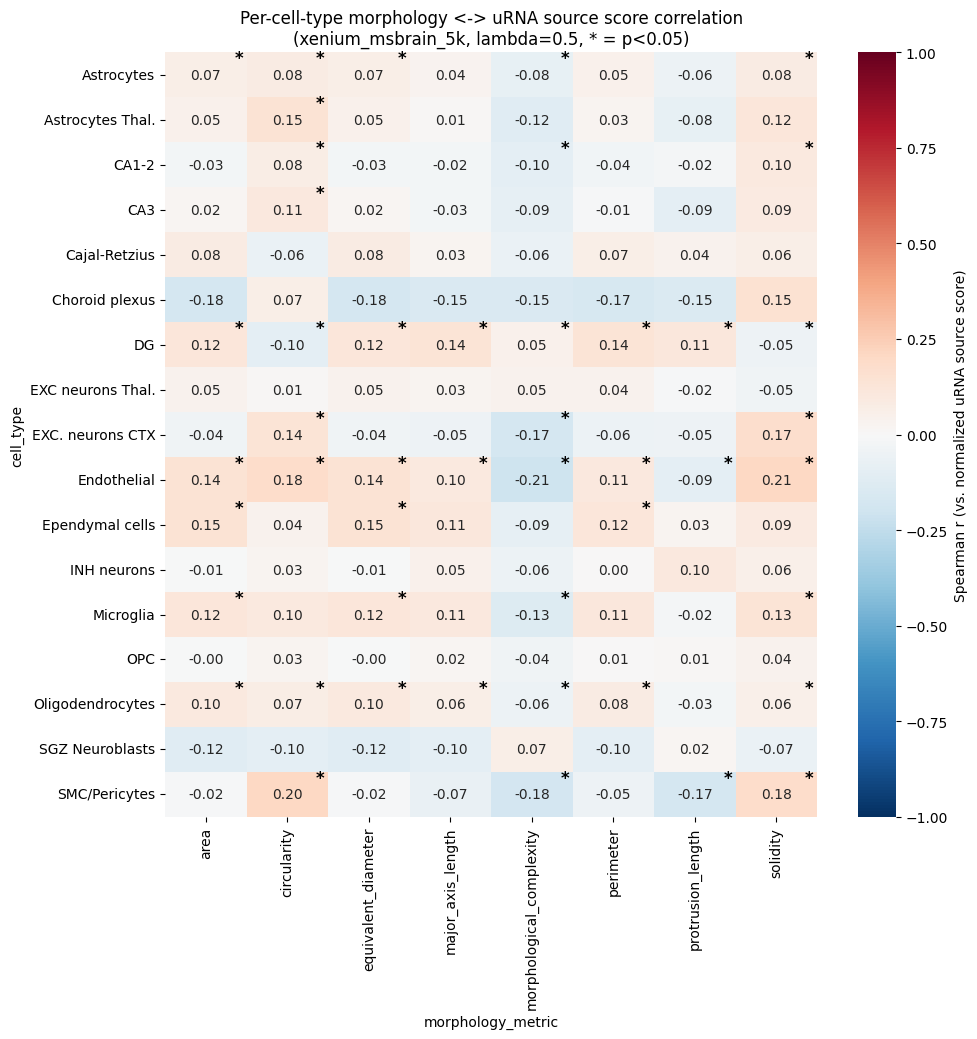

In [10]:
r_mat = celltype_corr_df.pivot(index="cell_type", columns="morphology_metric", values="spearman_r")
sig_mat = celltype_corr_df.pivot(index="cell_type", columns="morphology_metric", values="p_value") < 0.05

fig, ax = plt.subplots(figsize=(10, 0.5 * len(r_mat) + 2))
sns.heatmap(r_mat, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            cbar_kws={"label": "Spearman r (vs. normalized uRNA source score)"}, ax=ax)
for i, ct in enumerate(r_mat.index):
    for j, m in enumerate(r_mat.columns):
        if sig_mat.loc[ct, m]:
            ax.text(j + 0.85, i + 0.25, "*", color="black", fontsize=12, fontweight="bold")
ax.set_title("Per-cell-type morphology <-> uRNA source score correlation\n(xenium_msbrain_5k, lambda=0.5, * = p<0.05)")
plt.tight_layout()
plt.savefig(os.path.join(saving_path, "celltype_morphology_urna_heatmap.pdf"), format="pdf", bbox_inches="tight")
plt.show()

## Summary

- `celltype_morphology_urna_summary.csv`, `celltype_morphology_urna_correlations.csv`, and the
  three plots above saved to `ms_figures/xenium_msbrain_5k/morphology_urna_association/`.
- This notebook was created as a standalone file rather than appended to
  `5_computing_cell_scores_msbrain.ipynb` because that notebook was being actively executed and
  checkpointed by a live SLURM job (`nb5_msbrain_lambda05_ckpt`) at the time this was written —
  appending cells to it then risked the job's next per-cell checkpoint silently overwriting the
  addition. Once that job has finished, these cells can be merged into notebook 5 to sit
  alongside its other `cell_type`/`urna_source_score` figures, if desired.